In [1]:
%pip install -q legacy-cgi opendatasets ultralytics

In [2]:
import os
from ultralytics import YOLO
import random
import glob
from PIL import Image
from google.colab import files

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import torch

from sklearn.metrics import classification_report, confusion_matrix
from ultralytics.utils.metrics import box_iou

from IPython.display import Video, display
import cv2

import opendatasets as od

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
od.download("https://www.kaggle.com/datasets/anandpanda3/furniture-dataset-in-yolov8")

Dataset URL: https://www.kaggle.com/datasets/anandpanda3/furniture-dataset-in-yolov8


100%|██████████| 48.7M/48.7M [00:02<00:00, 19.4MB/s]


In [4]:
print(os.listdir("/content/furniture-dataset-in-yolov8"))

['README.dataset.txt', 'train', 'valid', 'data.yaml', 'README.roboflow.txt', 'test']


In [5]:
model = YOLO("yolov8n.pt")

results = model.train(
    data="/content/furniture-dataset-in-yolov8/data.yaml",
    epochs=20,
    imgsz=640,
    batch=16
)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/furniture-dataset-in-yolov8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimi

In [6]:
model = YOLO("/content/runs/detect/train/weights/best.pt")

results = model.val(
    data="/content/furniture-dataset-in-yolov8/data.yaml",
    split="test"
)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2178.3±587.5 MB/s, size: 66.7 KB)
val: Scanning /content/furniture-dataset-in-yolov8/test/labels... 74 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 74/74 2.1Kit/s 0.0s
val: New cache created: /content/furniture-dataset-in-yolov8/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.9it/s 2.6s
                   all         74         74      0.995      0.999      0.995      0.925
                 Chair         50         50       0.99          1      0.995      0.933
                  Sofa         24         24          1      0.998      0.995      0.918
Speed: 7.6ms preprocess, 10.5ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /content/runs/detect/val


Results saved to /content/runs/detect/predict


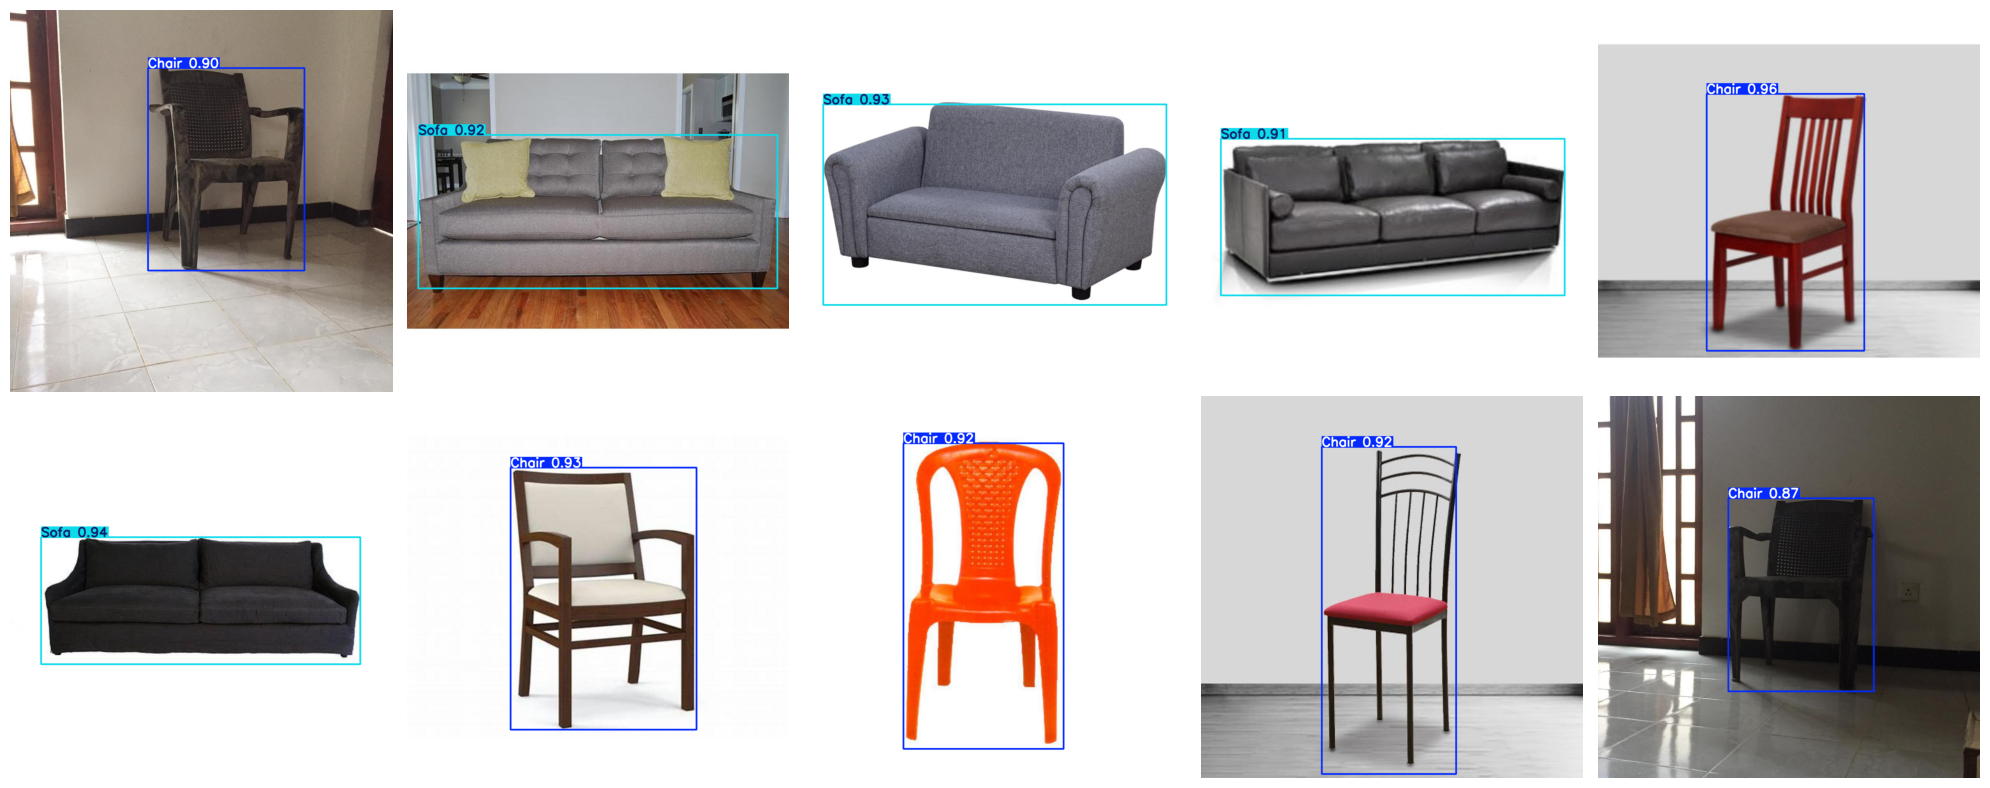

In [7]:
# Load your trained model
model = YOLO("/content/runs/detect/train/weights/best.pt")

# Get all test images
image_paths = glob.glob(
    "/content/furniture-dataset-in-yolov8/test/images/*"
)

# Randomly select up to 10 images
random_images = random.sample(
    image_paths,
    min(10, len(image_paths))
)

# Run prediction
results = model.predict(
    source=random_images,
    save=True,
    verbose=False
)

# Display predictions
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for ax in axes.flat:
    ax.axis("off")

for ax, result in zip(axes.flat, results):
    img = result.plot()
    img = img[:, :, ::-1]  # BGR to RGB

    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Upload your video
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a video.")

filename = next(iter(uploaded))
print("Uploaded:", filename)

# Load your trained furniture model
model_path = "/content/runs/detect/train/weights/best.pt"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        "best.pt was not found. Upload your trained model "
        "or restore it from Google Drive."
    )

model = YOLO(model_path)

# Open the video
cap = cv2.VideoCapture(filename)

if not cap.isOpened():
    raise ValueError("Could not open the uploaded video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Video resolution:", width, "x", height)
print("Total frames:", total_frames)

# Create output video
output_path = "/content/furniture_detected.mp4"

# MP4 codec
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    output_path, fourcc, fps if fps > 0 else 25,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the output video.")

# Process one frame at a time
frame_number = 0

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            break

        # Detect furniture in this frame
        result = model.predict(
            source=frame,
            imgsz=640,
            conf=0.25,
            verbose=False
        )[0]

        # Draw bounding boxes and labels
        annotated_frame = result.plot()

        # Write frame and release references
        writer.write(annotated_frame)
        del result, annotated_frame

        frame_number += 1

        if frame_number % 50 == 0:
            print(f"Processed {frame_number}/{total_frames} frames")

finally:
    cap.release()
    writer.release()

print("Finished processing!")
print("Saved video:", output_path)
print("File size (MB):", round(os.path.getsize(output_path) / (1024**2), 2))

# Download the result
files.download(output_path)


Saving Furniture_detector_testing_video.mp4 to Furniture_detector_testing_video.mp4
Uploaded: Furniture_detector_testing_video.mp4
Video resolution: 1080 x 1500
Total frames: 1590
Processed 50/1590 frames
Processed 100/1590 frames
Processed 150/1590 frames
Processed 200/1590 frames
Processed 250/1590 frames
Processed 300/1590 frames
Processed 350/1590 frames
Processed 400/1590 frames
Processed 450/1590 frames
Processed 500/1590 frames
Processed 550/1590 frames
Processed 600/1590 frames
Processed 650/1590 frames
Processed 700/1590 frames
Processed 750/1590 frames
Processed 800/1590 frames
Processed 850/1590 frames
Processed 900/1590 frames
Processed 950/1590 frames
Processed 1000/1590 frames
Processed 1050/1590 frames
Processed 1100/1590 frames
Processed 1150/1590 frames
Processed 1200/1590 frames
Processed 1250/1590 frames
Processed 1300/1590 frames
Processed 1350/1590 frames
Processed 1400/1590 frames
Processed 1450/1590 frames
Processed 1500/1590 frames
Processed 1550/1590 frames
Fin

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

https://www.youtube.com/watch?v=bUpXxzZV3CI